# Кого включить в пилот удержания

В тестовой выборке последующий уход подтвердился у 57 из 60 гостей с наибольшим прогнозным риском. Среди тех, кто был в кофейне в последние 45 дней, модель нашла 40 будущих уходов на 53 места акции. При том же бюджете сортировка по давности визита нашла 19. Это основание предложить пилот бонуса.

## 1. Срез на 1 октября

Объект — гость программы лояльности. Отток означает отсутствие визитов в следующие 60 дней. К моменту решения доступны признаки прошлой активности. Бюджет охватывает 10 % гостей. Сравню модель с постоянным прогнозом и текущим правилом. Для решения о бонусе сравню получателей при одинаковом бюджете.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
RANDOM_STATE=42

In [2]:
g=pd.read_csv(Path("../data/guests_churn.csv"))
churn_rate=round(g.churned.mean(),3)
na_check=g.avg_check.isna().sum()
na_no_visits=(g.loc[g.avg_check.isna(),"visits_90d"]==0).all()
churn_no_visits=round(g.loc[g.visits_90d==0,"churned"].mean(),3)
assert g.guest_id.is_unique
print(len(g),churn_rate,na_check,na_no_visits,churn_no_visits)

2400 0.223 144 True 0.882


In [3]:
filled=g.avg_check.isna().sum()
g["avg_check"]=g.avg_check.fillna(0)
v=g[g.visits_90d>0]
check_churned=round(v.loc[v.churned==1,"avg_check"].mean())
check_stayed=round(v.loc[v.churned==0,"avg_check"].mean())
print(check_churned,check_stayed)

343 342


Из 2 400 гостей ушли 22,3 %. Все 144 пропуска среднего чека относятся к гостям без визитов, поэтому для модели ввёл значение 0. Среди таких гостей ушли 88,2 %. У посещавших кофейни средние чеки ушедших и оставшихся близки, 343 и 342 ₽.

## 2. Отложенный тест и проверка утечки

In [4]:
y=g.churned
X=pd.get_dummies(g.drop(columns=["guest_id","churned","card_blocked"]),dtype=int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
train_rate,test_rate=round(y_train.mean(),3),round(y_test.mean(),3)
assert not set(X_train.index) & set(X_test.index)
dev=g.loc[X_train.index].copy()
cols=["tenure_months","app","visits_90d","days_since_last","avg_check","delivery_share","promo_used","complaints","card_blocked"]
print(len(X_train), len(X_test))

1800 600


In [5]:
a,b,u,v=train_test_split(dev[cols],dev.churned,test_size=.25,random_state=42,stratify=dev.churned)
m=DecisionTreeClassifier(max_depth=3,random_state=0).fit(a,u)
acc_all=round(m.score(b,v),3)
top_feature=a.columns[m.feature_importances_.argmax()]
m=DecisionTreeClassifier(max_depth=3,random_state=0).fit(a.drop(columns=top_feature),u)
acc_clean=round(m.score(b.drop(columns=top_feature),v),3)
blocked_churn=round(dev.loc[dev.card_blocked==1,"churned"].mean(),3)
print(top_feature,acc_all,acc_clean,blocked_churn)

card_blocked 0.978 0.831 0.957


Отложил 600 гостей для итоговой проверки. На диагностическом разбиении внутри остальных 1 800 гостей дерево с признаком блокировки даёт 97,8 %, а без него — 83,1 %. Блокировка появляется после 60 дней без визита. Чтобы исключить будущее из прогноза, исключил этот столбец вместе с целевым признаком и идентификатором.

## 3. Сравнение на одинаковых фолдах

In [6]:
kf=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
base_cv=round(np.mean([(y_train.iloc[v]==0).mean() for _,v in kf.split(X_train)]),3)
rule_cv=round(np.mean([((X_train.days_since_last.iloc[v]>45)==y_train.iloc[v]).mean() for _,v in kf.split(X_train)]),3)
print(base_cv,rule_cv)

0.777 0.823


In [7]:
cv_depth={}
for depth in range(1,11):
    m=DecisionTreeClassifier(max_depth=depth,random_state=0)
    cv_depth[depth]=cross_val_score(m,X_train,y_train,cv=kf).mean()
best_depth=max(cv_depth,key=cv_depth.get)
best_cv=round(cv_depth[best_depth],3)
print(best_depth,best_cv)

4 0.856


In [8]:
models={"дерево":DecisionTreeClassifier(max_depth=best_depth,random_state=0),"лес":RandomForestClassifier(n_estimators=100,min_samples_leaf=3,random_state=0),"логрегрессия":LogisticRegression(max_iter=2000)}
scores={name:cross_val_score(m,X_train,y_train,cv=kf) for name,m in models.items()}
table=pd.DataFrame.from_dict({name:{"mean":vals.mean(),"std":vals.std()} for name,vals in scores.items()},orient="index").sort_values("mean",ascending=False).round(3)
winner=table.index[0]
table

,mean,std
лес,0.866,0.028
дерево,0.856,0.018
логрегрессия,0.856,0.025


База дала 77,7 %, правило 45 дней — 82,3 %. Лучшая глубина дерева — 4. На CV средний результат леса 86,6 %, дерева и логистической регрессии — по 85,6 %. Отрыв невелик. Для финальной проверки взял лес как лидера по заранее выбранному среднему accuracy.

## 4. Отложенная выборка и бюджет акции

In [9]:
model=models[winner].fit(X_train,y_train)
test_acc=round(model.score(X_test,y_test),3)
base_test=round((y_test==0).mean(),3)
rule_test=round(((X_test.days_since_last>45)==y_test).mean(),3)
print(test_acc,base_test,rule_test)

0.898 0.777 0.852


In [10]:
risk=pd.Series(model.predict_proba(X_test)[:,1],index=X_test.index)
top=risk.nlargest(60)
top_ids=g.loc[top.index,"guest_id"].tolist()
rate=y_test.loc[top.index].mean()
top_rate=round(rate,3)
lift=round(rate/y_test.mean(),1)
already_gone=round((X_test.loc[top.index,"days_since_last"]>45).mean(),3)
print(top_rate,lift,already_gone)
campaign=g.loc[top.index,["guest_id"]].assign(risk=top)
display(campaign.head())
campaign.to_csv("../campaign.csv",index=False)

0.95 4.3 0.667


,guest_id,risk
563,G-10564,0.985408
2164,G-12165,0.968731
1094,G-11095,0.967552
1589,G-11590,0.960705
938,G-10939,0.950280


134 57 535 53 0.148 0.755 0.358


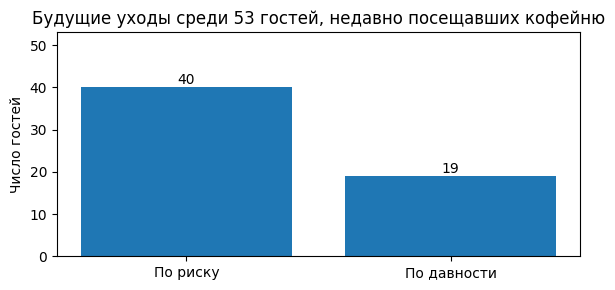

In [11]:
v=X_test[X_test.days_since_last<=45]
quiet_rate=round(y_test.loc[v.index].mean(),3)
k=int(len(v)*.1)
r=pd.Series(model.predict_proba(v)[:,1],index=v.index)
model_rate=round(y_test.loc[r.nlargest(k).index].mean(),3)
days_rate=round(y_test.loc[v.days_since_last.nlargest(k).index].mean(),3)
r_all=y_test.loc[top.index].sum()
r_model=y_test.loc[r.nlargest(k).index].sum()
r_days=y_test.loc[v.days_since_last.nlargest(k).index].sum()
print(y_test.sum(),r_all,len(v),k,quiet_rate,model_rate,days_rate)
fig,ax=plt.subplots(figsize=(6,3))
bars=ax.bar(["По риску","По давности"],[r_model,r_days])
ax.bar_label(bars)
ax.set(title="Будущие уходы среди 53 гостей, недавно посещавших кофейню",ylabel="Число гостей",ylim=(0,k))
fig.tight_layout()
plt.show()

В финальном тесте accuracy леса 89,8 %, правила 85,2 %, постоянного прогноза 77,7 %. Среди топ-60 ушло 57 из 134 всех ушедших. Риск-список накрыл 42,5 % будущих уходов с лифтом 4,3. Из отобранных 40 уже подпадают под правило 45 дней, поэтому отдельно сравнил списки среди 535 ещё активных гостей.

## 5. Выводы и рекомендации

В группе недавних посетителей будущий отток равен 14,8 %. Из 53 отобранных моделью ушли 75,5 %, при отборе по давности — 35,8 %. Для проверки эффекта бонуса предложил бы выделить случайную контрольную группу среди подходящих получателей и сравнить дополнительные визиты и маржу после расходов на бонус. В этих данных нет назначения бонуса и результата такого эксперимента. Все гости относятся к одному календарному срезу, поэтому перенос результата на следующий месяц пока не проверен.